#### Importation des modules et du dataset d'entrainement

In [1]:
# Importation des modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from optbinning import MulticlassOptimalBinning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from scipy.stats import kruskal
from scipy.stats import chi2_contingency

In [2]:
# Importation du dataset d'entrainement
df = pd.read_csv("../data/Train.csv")

Description des variables

| Variable | Description |
|---|---|
| `ID` | Identifiant unique du client |
| `Gender` | Genre du client |
| `Ever_Married` | État civil du client |
| `Age` | Âge du client |
| `Graduated` | Indique si le client est diplômé |
| `Profession` | Profession du client |
| `Work_Experience` | Expérience professionnelle (en années) |
| `Spending_Score` | Score de dépenses du client |
| `Family_Size` | Nombre de membres dans la famille (client inclus) |
| `Var_1` | Catégorie anonymisée du client |
| `Segmentation` | Segment cible du client *(variable à prédire)* |

In [3]:
print(df.info())
print(df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 8068 entries, 0 to 8067
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               8068 non-null   int64  
 1   Gender           8068 non-null   str    
 2   Ever_Married     7928 non-null   str    
 3   Age              8068 non-null   int64  
 4   Graduated        7990 non-null   str    
 5   Profession       7944 non-null   str    
 6   Work_Experience  7239 non-null   float64
 7   Spending_Score   8068 non-null   str    
 8   Family_Size      7733 non-null   float64
 9   Var_1            7992 non-null   str    
 10  Segmentation     8068 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 693.5 KB
None
(8068, 11)


In [4]:
# Split Train Test

X = df.drop('Segmentation', axis=1)
y = df['Segmentation']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                      stratify=y, random_state=42)

print(f"Train : {X_train.shape[0]} lignes")
print(f"Test  : {X_test.shape[0]} lignes")

Train : 6454 lignes
Test  : 1614 lignes


In [5]:
num_vars = ['Age', 'Work_Experience', 'Family_Size']
cat_vars = ['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score', 'Var_1']
# target = ['Segmentation']

##### Analyse Univariée

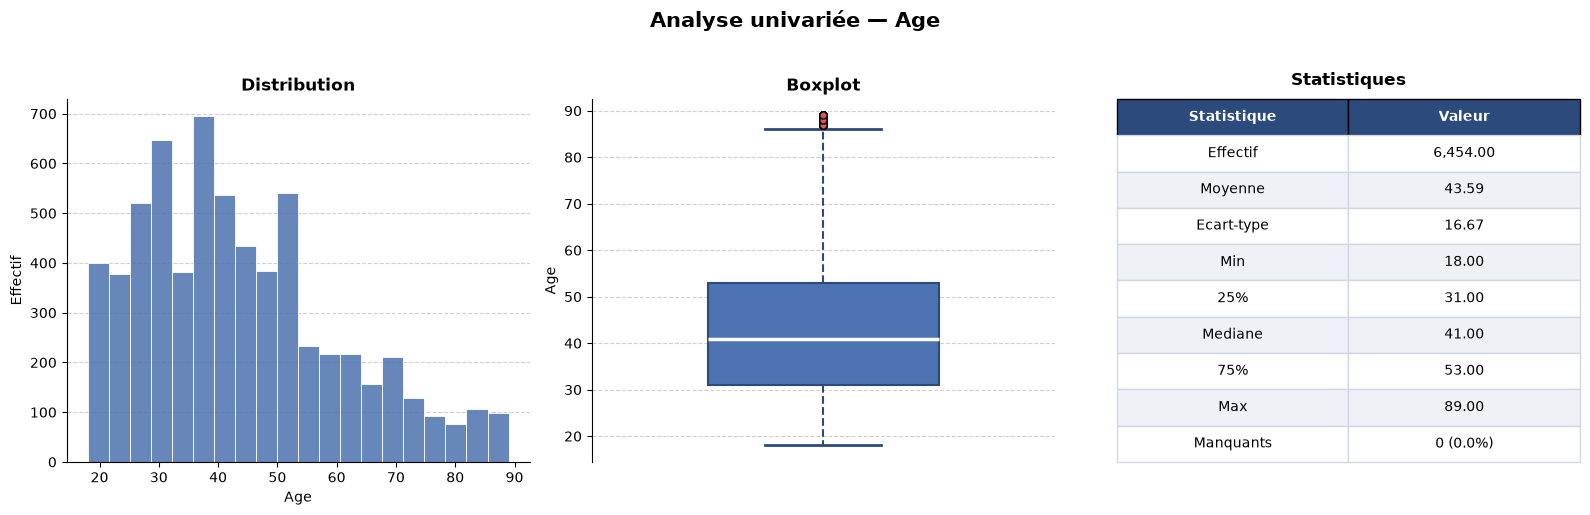

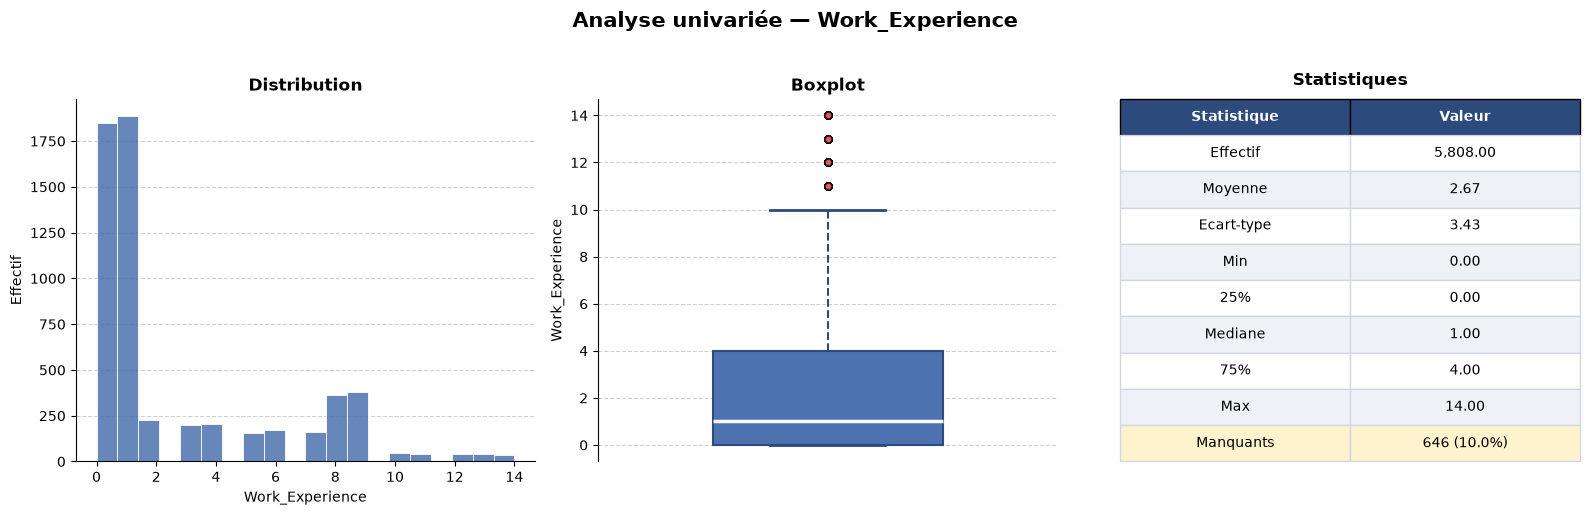

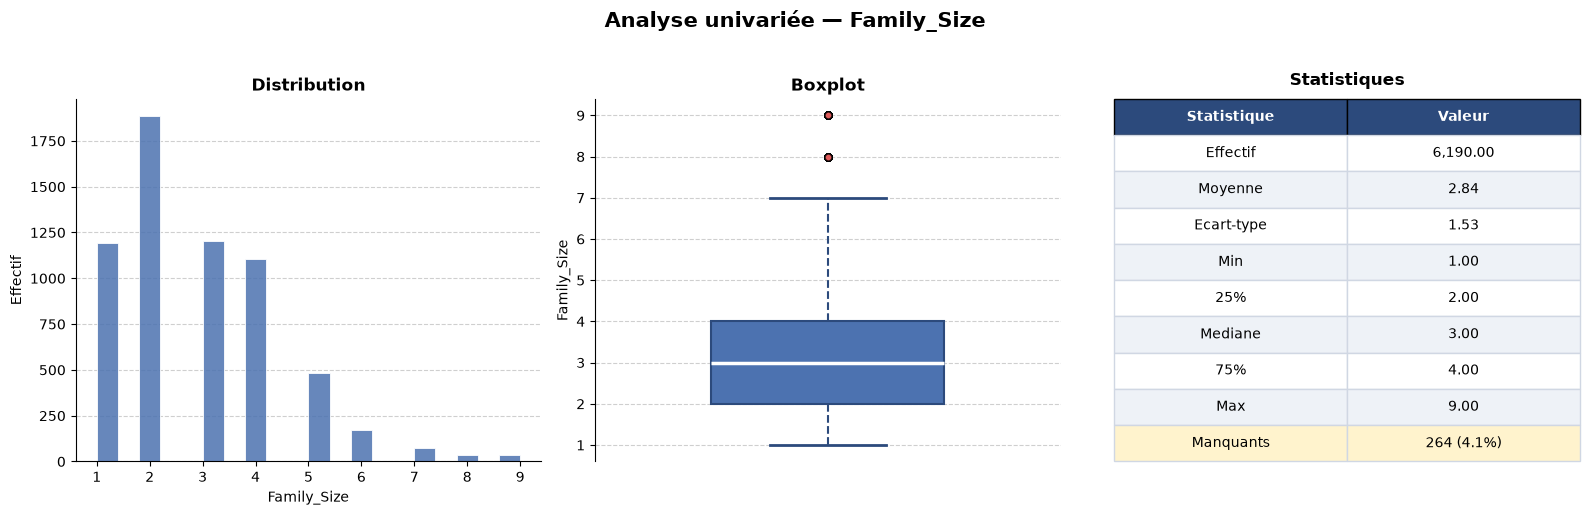

In [6]:
## Analyse Univariée des variables quantitatives

warnings.filterwarnings('ignore')

for col in num_vars:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(f'Analyse univariée — {col}', fontsize=15, fontweight='bold', y=1.02)

    color_main = '#4C72B0'
    color_dark  = '#2c4a7c'

    # --- Histogramme ---
    ax = axes[0]
    ax.hist(X_train[col].dropna(), bins=20, color=color_main,
            edgecolor='white', linewidth=0.7, alpha=0.85)

    ax.set_title('Distribution', fontsize=12, fontweight='bold')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Effectif', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

    # --- Boxplot ---
    ax = axes[1]
    bp = ax.boxplot(X_train[col].dropna(), patch_artist=True, orientation='vertical',
                    widths=0.5,
                    boxprops=dict(facecolor=color_main, color=color_dark, linewidth=1.5),
                    medianprops=dict(color='white', linewidth=2.5),
                    whiskerprops=dict(color=color_dark, linewidth=1.5, linestyle='--'),
                    capprops=dict(color=color_dark, linewidth=2),
                    flierprops=dict(marker='o', color=color_dark,
                                   markerfacecolor='#e05c5c', markersize=5, alpha=0.7))

    ax.set_title('Boxplot', fontsize=12, fontweight='bold')
    ax.set_ylabel(col, fontsize=10)
    ax.set_xticks([])
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'bottom']].set_visible(False)

    # --- Stats descriptives ---
    ax = axes[2]
    ax.axis('off')

    stats = X_train[col].describe().round(2)
    missing = X_train[col].isnull().sum()
    missing_pct = X_train[col].isnull().mean() * 100

    labels = {
        'count': 'Effectif', 'mean': 'Moyenne', 'std': 'Ecart-type',
        'min': 'Min', '25%': '25%', '50%': 'Mediane',
        '75%': '75%', 'max': 'Max'
    }

    table_data = [[labels.get(k, k), f"{v:,.2f}"] for k, v in stats.items()]
    table_data.append(['Manquants', f"{missing} ({missing_pct:.1f}%)"])

    table = ax.table(
        cellText=table_data,
        colLabels=['Statistique', 'Valeur'],
        loc='center', cellLoc='center',
        bbox=[0, 0, 1, 1]
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10)

    for j in range(2):
        table[0, j].set_facecolor(color_dark)
        table[0, j].set_text_props(color='white', fontweight='bold')

    for i in range(1, len(table_data) + 1):
        for j in range(2):
            table[i, j].set_facecolor('#eef2f7' if i % 2 == 0 else 'white')
            table[i, j].set_edgecolor('#d0d7e3')

    if missing > 0:
        for j in range(2):
            table[len(table_data), j].set_facecolor('#fff3cd')

    ax.set_title('Statistiques', fontsize=12, fontweight='bold', pad=10)

    plt.tight_layout()
    plt.show()

In [7]:
## Discrétisation des variables quantitatives
binners = {}

for col in num_vars:

    optb = MulticlassOptimalBinning(name=col)  # ← pas de dtype

    mask = X_train[col].notna() & y_train.notna()
    optb.fit(X_train.loc[mask, col].values, y_train[mask].values)

    print(f"=== {col} ===")
    print(optb.binning_table.build())

    X_train[f'{col}_bin'] = optb.transform(X_train[col].values, metric="bins")
    binners[col] = optb

# Appliquer sur X_test
for col in num_vars:
    X_test[f'{col}_bin'] = binners[col].transform(X_test[col].values, metric="bins")


=== Age ===
                   Bin  Count  Count (%)  Event_A  Event_B  Event_C  Event_D  \
0        (-inf, 24.00)    607   0.094050       20       19       29      539   
1       [24.00, 28.50)    692   0.107220      170       94       94      334   
2       [28.50, 34.00)    831   0.128757      230      113      117      371   
3       [34.00, 44.00)   1620   0.251007      557      456      333      274   
4         [44.00, inf)   2704   0.418965      601      804     1003      296   
5              Special      0   0.000000        0        0        0        0   
6              Missing      0   0.000000        0        0        0        0   
Totals                   6454   1.000000     1578     1486     1576     1814   

        Event_rate_A  Event_rate_B  Event_rate_C  Event_rate_D  
0           0.032949      0.031301      0.047776      0.887974  
1           0.245665      0.135838      0.135838      0.482659  
2           0.276775      0.135981      0.140794      0.446450  
3      

In [ ]:
# # 1. Imputer Work_Experience
# train['Work_Experience'].fillna(train['Work_Experience'].median(), inplace=True)

# # 2. Imputer Family_Size
# train['Family_Size'].fillna(train['Family_Size'].median(), inplace=True)

# # 3. Log-transform Work_Experience
# import numpy as np
# train['Work_Experience_log'] = np.log1p(train['Work_Experience'])


# (penser aussi à la standardiser les var_num au cas où je fais la reg log, la log-transformation c'est aussi pour la reg log)

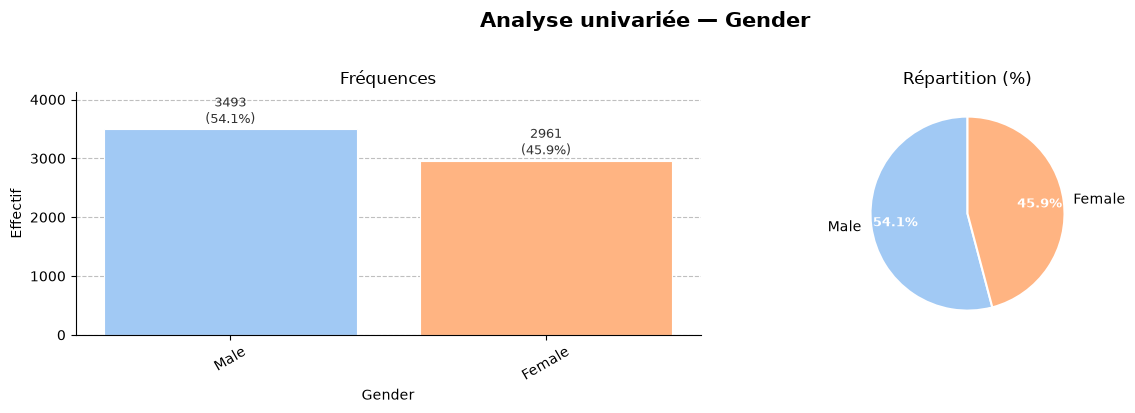

→ Modalités : 2
→ Valeurs manquantes : 0 (0.0%)


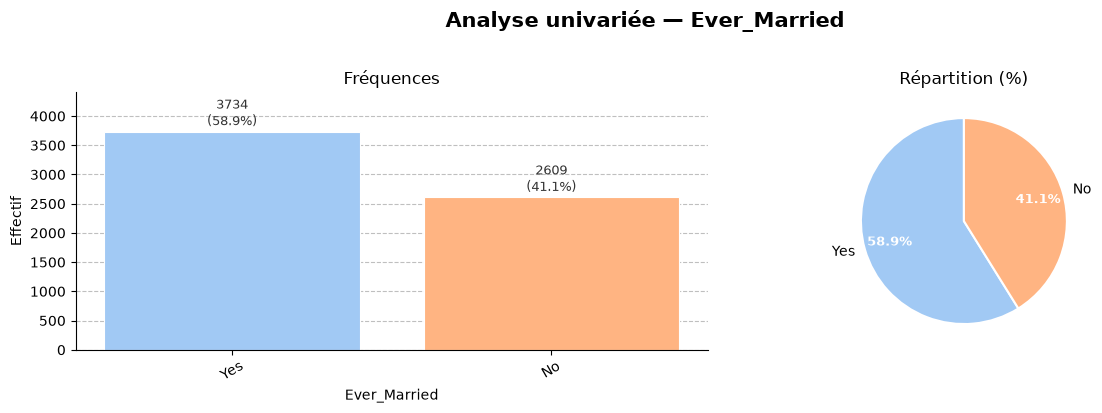

→ Modalités : 2
→ Valeurs manquantes : 111 (1.7%)


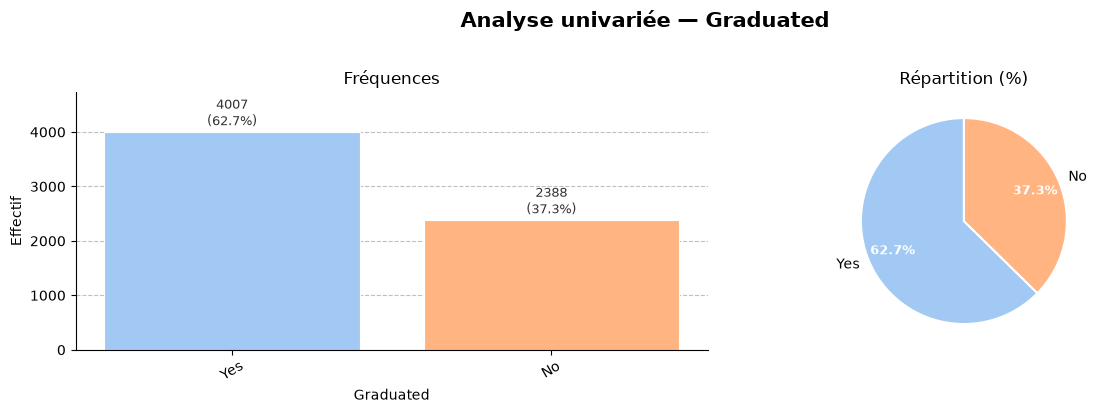

→ Modalités : 2
→ Valeurs manquantes : 59 (0.9%)


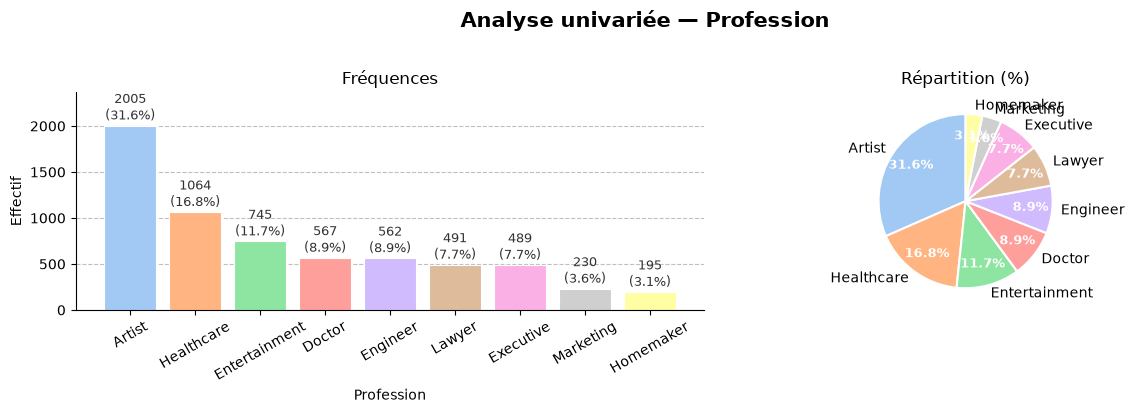

→ Modalités : 9
→ Valeurs manquantes : 106 (1.6%)


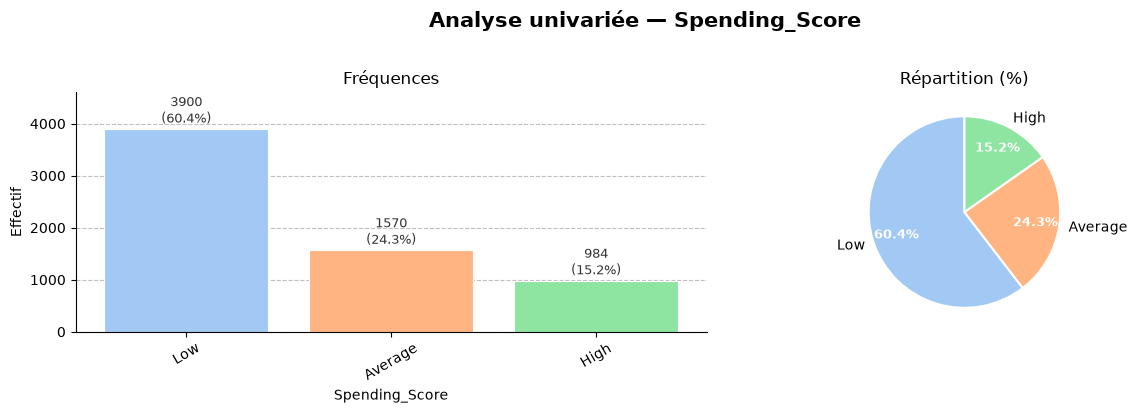

→ Modalités : 3
→ Valeurs manquantes : 0 (0.0%)


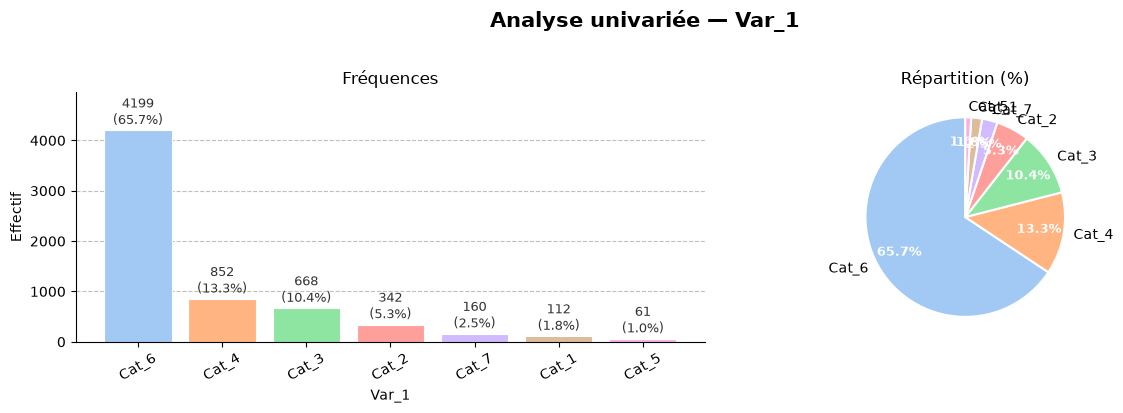

→ Modalités : 7
→ Valeurs manquantes : 60 (0.9%)


In [8]:
## Analyse Univariée des variables catégorielles

for col in cat_vars:
    counts = X_train[col].value_counts()
    pcts = X_train[col].value_counts(normalize=True) * 100
    n = len(counts)

    # Palette dynamique selon le nombre de modalités
    palette = sns.color_palette("pastel", n)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle(f'Analyse univariée — {col}', fontsize=15, fontweight='bold', y=1.02)

    # --- Bar chart ---
    bars = axes[0].bar(counts.index.astype(str), counts.values,
                       color=palette, edgecolor='white', linewidth=0.8)

    # Annotations au-dessus des barres
    for bar, val, pct in zip(bars, counts.values, pcts.values):
        axes[0].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + max(counts.values) * 0.01,
                     f'{val}\n({pct:.1f}%)',
                     ha='center', va='bottom', fontsize=9, color='#333333')

    axes[0].set_title('Fréquences', fontsize=12)
    axes[0].set_xlabel(col, fontsize=10)
    axes[0].set_ylabel('Effectif', fontsize=10)
    axes[0].tick_params(axis='x', rotation=30)
    axes[0].set_ylim(0, max(counts.values) * 1.18)
    axes[0].grid(axis='y', linestyle='--', alpha=0.5, color='gray')
    axes[0].set_axisbelow(True)
    axes[0].spines[['top', 'right']].set_visible(False)

    # --- Pie chart ---
    wedges, texts, autotexts = axes[1].pie(
        counts.values,
        labels=counts.index.astype(str),
        autopct='%1.1f%%',
        startangle=90,
        colors=palette,
        wedgeprops=dict(edgecolor='white', linewidth=1.5),
        pctdistance=0.75
    )
    for at in autotexts:
        at.set_fontsize(9)
        at.set_color('white')
        at.set_fontweight('bold')
    axes[1].set_title('Répartition (%)', fontsize=12)

    plt.tight_layout()
    plt.show()

    # Résumé texte
    print(f"→ Modalités : {X_train[col].nunique()}")
    print(f"→ Valeurs manquantes : {X_train[col].isnull().sum()} ({X_train[col].isnull().mean()*100:.1f}%)")
    # print(pd.DataFrame({'Effectif': counts, 'Pourcentage (%)': pcts.round(1)}), '\n')

In [9]:
# # Regroupement de la variable Profession
# profession_map = {
#     'Artist':         'Creative',
#     'Entertainment':  'Creative',
#     'Healthcare':     'Healthcare',
#     'Doctor':         'Healthcare',
#     'Engineer':       'Engineer',
#     'Lawyer':         'Lawyer',
#     'Executive':      'Executive',
#     'Marketing':      'Other',
#     'Homemaker':      'Other'
# }


# Nouveau regroupement de la variable Profession au vu de la différence de répartition des modalités
# par rapport à la variable cible
profession_map = {
    'Artist':         'Artist',
    'Entertainment':  'Entertainment',
    'Healthcare':     'Healthcare',
    'Doctor':         'Doctor',
    'Engineer':       'Engineer',
    'Lawyer':         'Lawyer',
    'Executive':      'Executive',
    'Marketing':      'Other',
    'Homemaker':      'Other'
}

X_train['Profession_group'] = X_train['Profession'].map(profession_map)
X_test['Profession_group'] = X_test['Profession'].map(profession_map)

## Regroupement Var_1
Var_1_map = {
    'Cat_6':  'Cat_6',
    'Cat_4':  'Cat_4',
    'Cat_3':   'Cat_3',
    'Cat_2':   'Other',
    'Cat_7':   'Other',
    'Cat_1':   'Other',
    'Cat_5':   'Other',
}

X_train['Var_1_group'] = X_train['Var_1'].map(Var_1_map)
X_test['Var_1_group'] = X_test['Var_1'].map(Var_1_map)

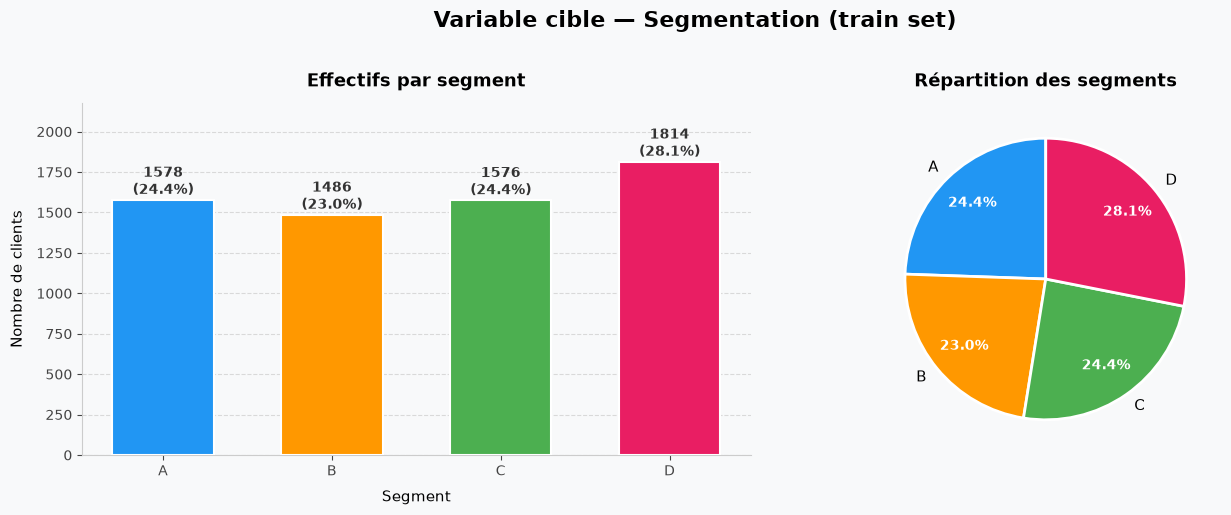

In [10]:
# Target

colors = ['#2196F3', '#FF9800', '#4CAF50', '#E91E63']
counts = y_train.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Variable cible — Segmentation (train set)', fontsize=16, fontweight='bold', y=1.02)
fig.patch.set_facecolor('#F8F9FA')

# ── Bar chart ──────────────────────────────────────────
ax = axes[0]
ax.set_facecolor('#F8F9FA')

bars = ax.bar(counts.index.astype(str), counts.values,
              color=colors, edgecolor='white', linewidth=1.5,
              width=0.6, zorder=3)

# Annotations valeurs + pourcentages
for bar, val in zip(bars, counts.values):
    pct = val / len(y_train) * 100
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 8,
            f'{val}\n({pct:.1f}%)', ha='center', va='bottom',
            fontsize=10, fontweight='bold', color='#333333')

ax.set_title('Effectifs par segment', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Segment', fontsize=11, labelpad=8)
ax.set_ylabel('Nombre de clients', fontsize=11, labelpad=8)
ax.set_ylim(0, counts.max() * 1.2)
ax.yaxis.grid(True, linestyle='--', alpha=0.7, color='#CCCCCC', zorder=0)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color('#CCCCCC')
ax.tick_params(axis='both', labelsize=10, colors='#444444')

# ── Pie chart ──────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#F8F9FA')

wedges, texts, autotexts = ax2.pie(
    counts.values,
    labels=counts.index.astype(str),
    autopct='%1.1f%%',
    startangle=90,
    colors=colors,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2),
    textprops=dict(fontsize=11)
)

for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')
    autotext.set_color('white')

ax2.set_title('Répartition des segments', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

- Pas de déséquilibre

##### Analyse Bivariée

In [11]:
target = 'Segmentation'
colors = ['#2196F3', '#FF9800', '#4CAF50', '#E91E63']

df_train = X_train.copy()
df_train[target] = y_train.values

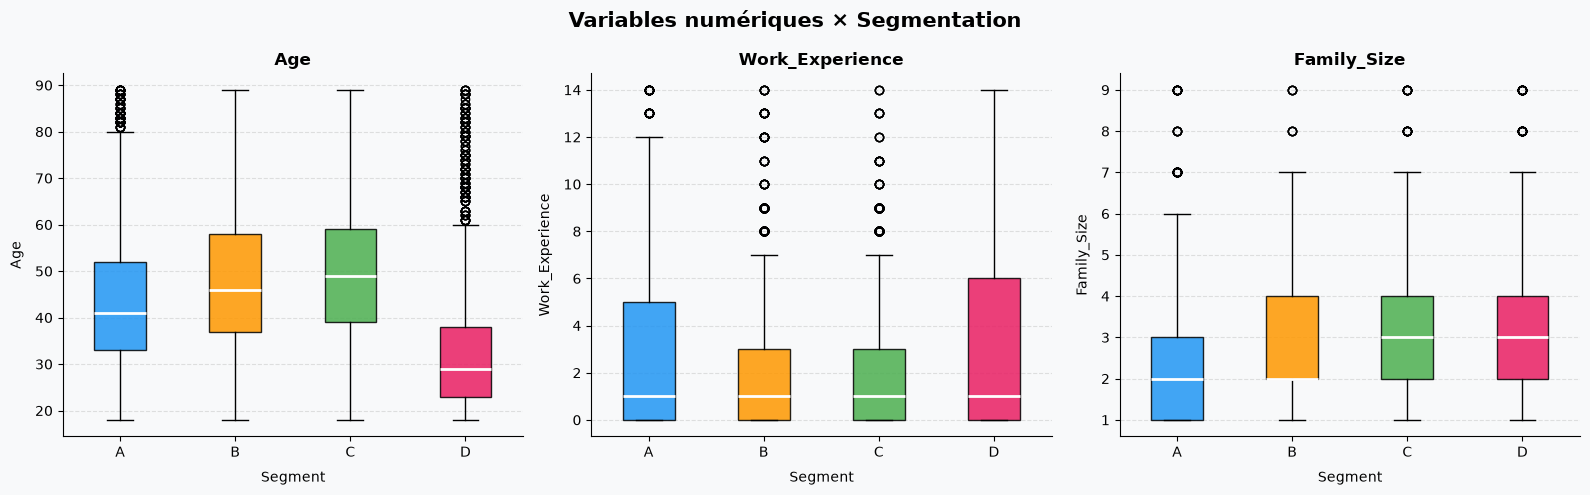

In [12]:
fig, axes = plt.subplots(1, len(num_vars), figsize=(16, 5))
fig.suptitle('Variables numériques × Segmentation', fontsize=15, fontweight='bold')
fig.patch.set_facecolor('#F8F9FA')

for ax, col in zip(axes, num_vars):
    ax.set_facecolor('#F8F9FA')
    data = [df_train[df_train[target] == seg][col].dropna()
            for seg in sorted(df_train[target].unique())]

    bp = ax.boxplot(data, patch_artist=True, notch=False,
                    medianprops=dict(color='white', linewidth=2))

    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.85)

    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xticklabels(sorted(df_train[target].unique()), fontsize=10)
    ax.set_xlabel('Segment', labelpad=8)
    ax.set_ylabel(col, labelpad=8)
    ax.yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

In [13]:
# Flag : 0 ou 1 an d'expérience
X_train['is_inexperienced'] = X_train['Work_Experience'].apply(
    lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
)
X_test['is_inexperienced'] = X_test['Work_Experience'].apply(
    lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
)

df_train['is_inexperienced'] = df_train['Work_Experience'].apply(
    lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
)

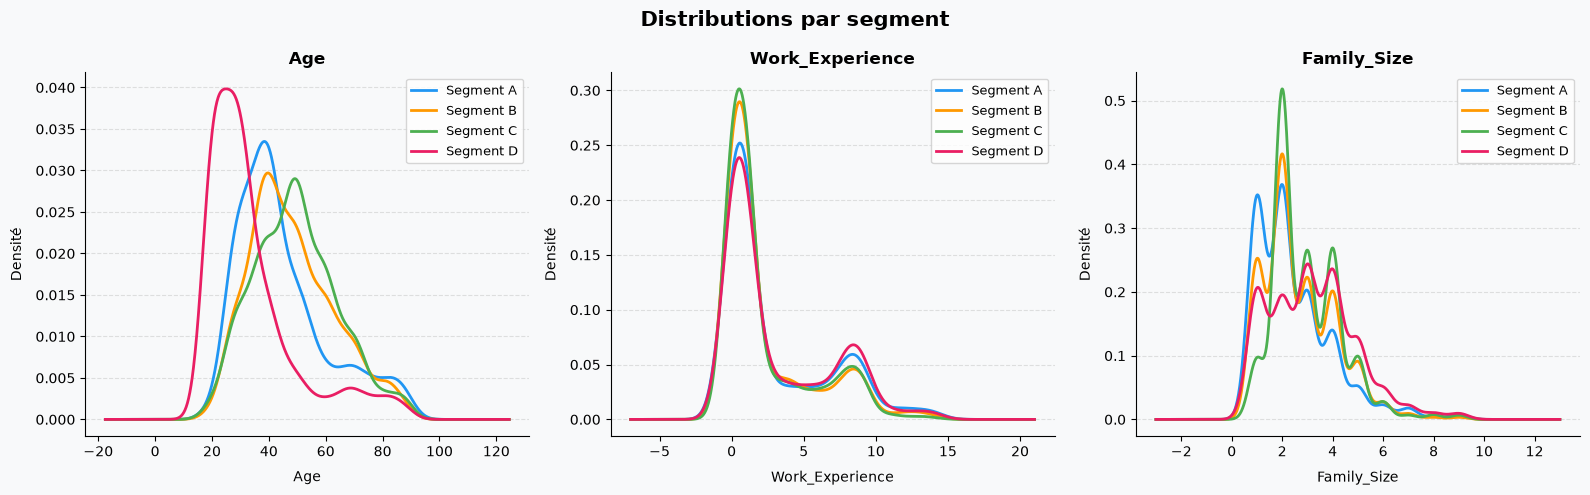

In [14]:
fig, axes = plt.subplots(1, len(num_vars), figsize=(16, 5))
fig.suptitle('Distributions par segment', fontsize=15, fontweight='bold')
fig.patch.set_facecolor('#F8F9FA')

for ax, col in zip(axes, num_vars):
    ax.set_facecolor('#F8F9FA')
    for seg, color in zip(sorted(df_train[target].unique()), colors):
        subset = df_train[df_train[target] == seg][col].dropna()
        subset.plot.kde(ax=ax, label=f'Segment {seg}', color=color, linewidth=2)

    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.set_xlabel(col, labelpad=8)
    ax.set_ylabel('Densité', labelpad=8)
    ax.legend(fontsize=9)
    ax.yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

In [15]:

for col in num_vars:
    groups = [df_train[df_train['Segmentation'] == seg][col].dropna()
          for seg in sorted(df_train['Segmentation'].unique())]

    stat, p = kruskal(*groups)
    print(f"H_{col}={stat:.3f}, p_{col}={p:.4f}")

H_Age=1344.868, p_Age=0.0000
H_Work_Experience=38.870, p_Work_Experience=0.0000
H_Family_Size=251.002, p_Family_Size=0.0000


D'après le test de kruskal-Wallis, l'Age, l'expérience de travail et la taille de la famille ont un impact significatif sur la segmentation client

In [16]:
# cat_vars_group = ['Profession', 'Profession_group', 'Var_1', 'Var_1_group']
new_cat_vars = ['Gender', 'Ever_Married', 'Graduated', 'Profession_group', 'Spending_Score', 'Var_1_group', 'is_inexperienced']

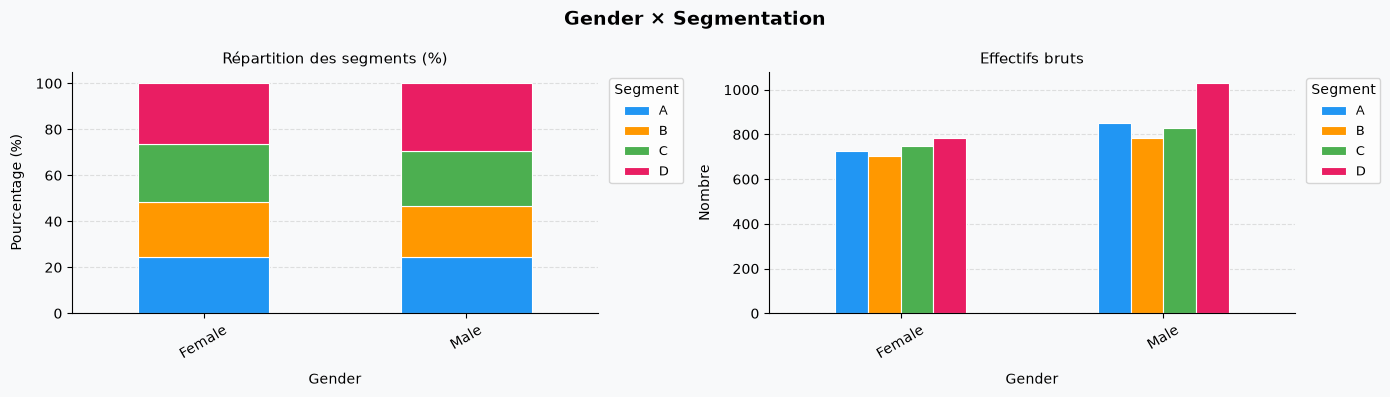

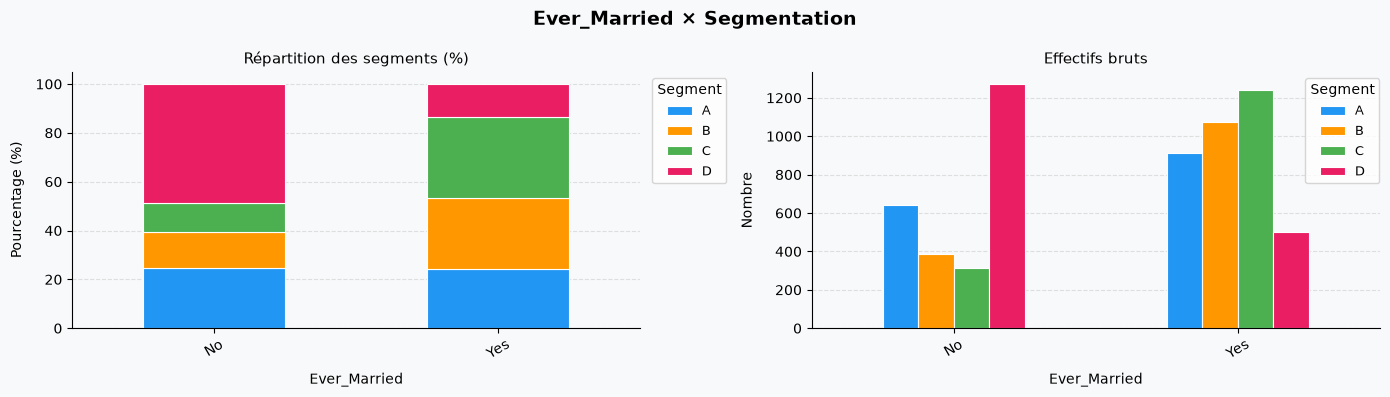

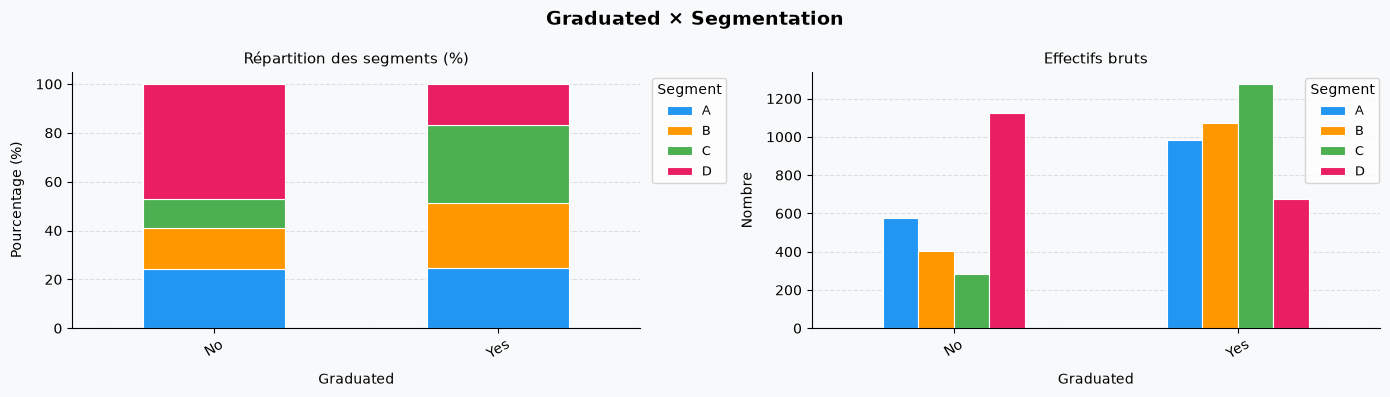

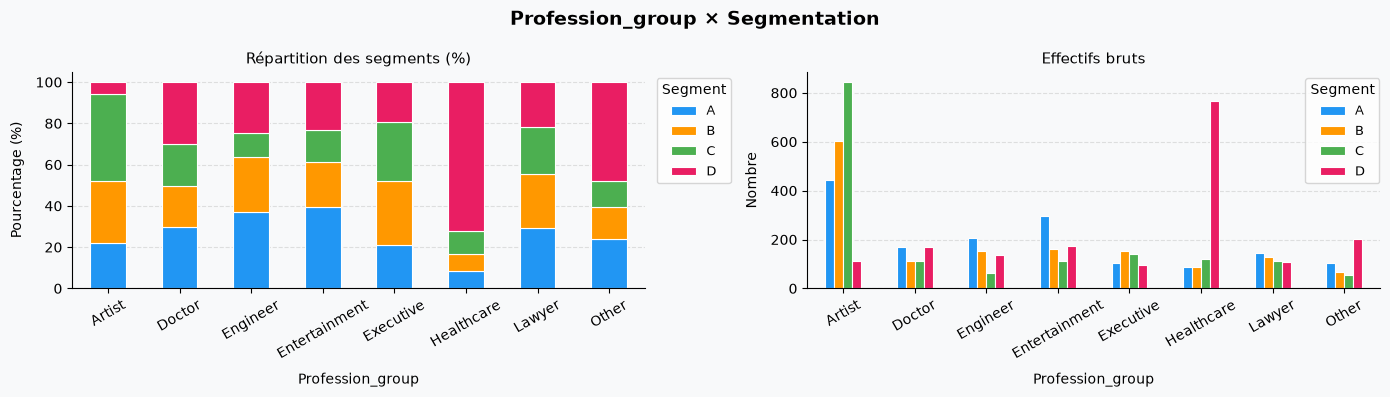

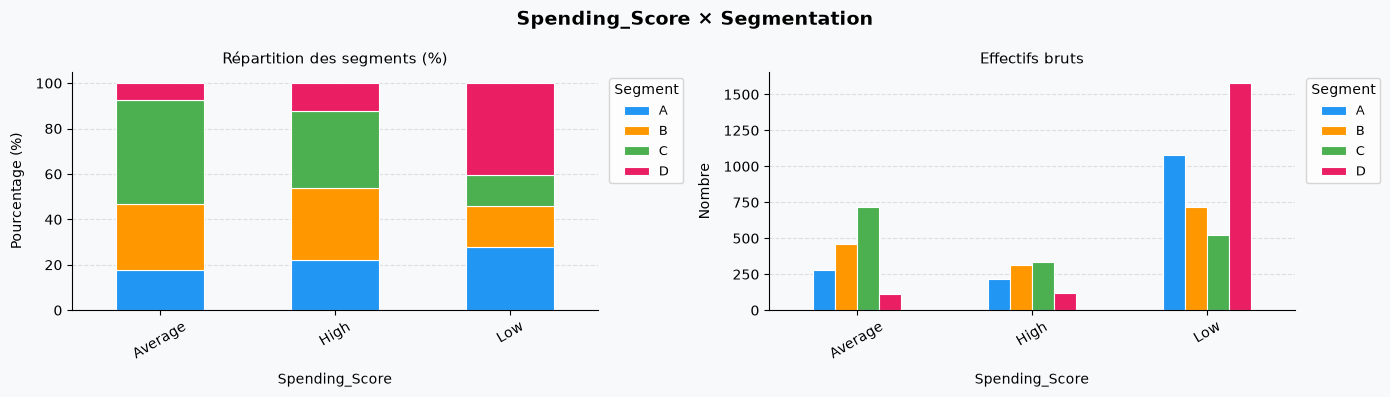

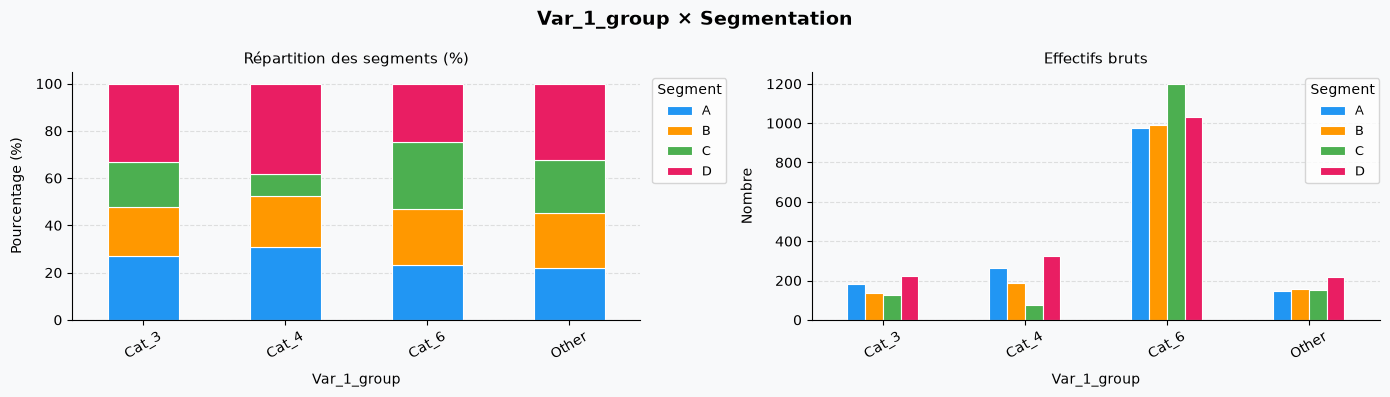

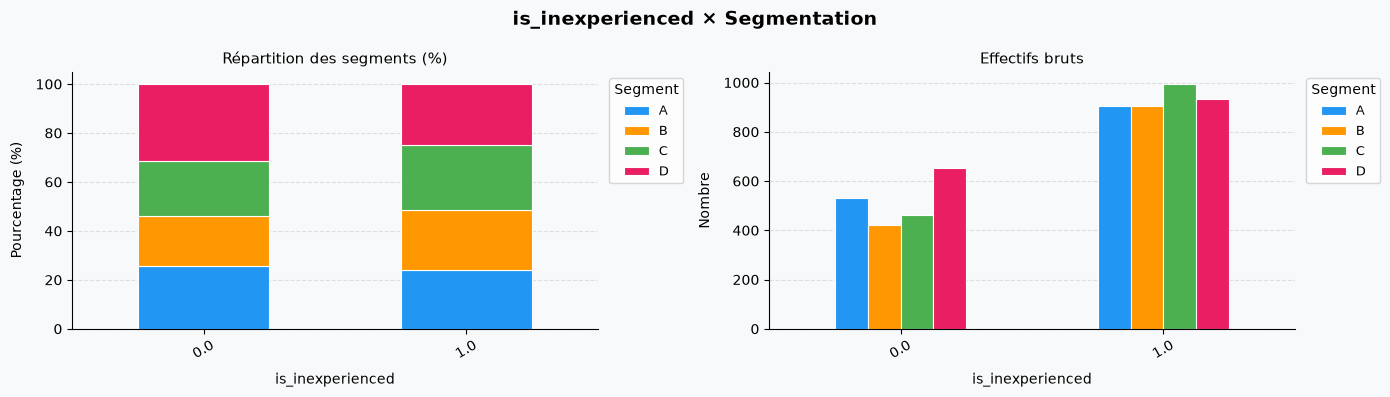

In [17]:
for col in new_cat_vars:
    ct = pd.crosstab(df_train[col], df_train[target], normalize='index') * 100

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'{col} × Segmentation', fontsize=14, fontweight='bold')
    fig.patch.set_facecolor('#F8F9FA')

    # Barres empilées normalisées
    ct.plot(kind='bar', stacked=True, ax=axes[0],
            color=colors, edgecolor='white', linewidth=0.8)
    axes[0].set_title('Répartition des segments (%)', fontsize=11)
    axes[0].set_xlabel(col, labelpad=8)
    axes[0].set_ylabel('Pourcentage (%)', labelpad=8)
    axes[0].set_facecolor('#F8F9FA')
    axes[0].legend(title='Segment', bbox_to_anchor=(1.01, 1), fontsize=9)
    axes[0].tick_params(axis='x', rotation=30)
    axes[0].yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    axes[0].set_axisbelow(True)
    axes[0].spines[['top', 'right']].set_visible(False)

    # Effectifs bruts
    ct_raw = pd.crosstab(df_train[col], df_train[target])
    ct_raw.plot(kind='bar', ax=axes[1],
                color=colors, edgecolor='white', linewidth=0.8)
    axes[1].set_title('Effectifs bruts', fontsize=11)
    axes[1].set_xlabel(col, labelpad=8)
    axes[1].set_ylabel('Nombre', labelpad=8)
    axes[1].set_facecolor('#F8F9FA')
    axes[1].legend(title='Segment', bbox_to_anchor=(1.01, 1), fontsize=9)
    axes[1].tick_params(axis='x', rotation=30)
    axes[1].yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    axes[1].set_axisbelow(True)
    axes[1].spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.show()

In [18]:
def cramers_v(col1, col2):
    ct = pd.crosstab(col1, col2)
    chi2, _, _, _ = chi2_contingency(ct)
    n = ct.sum().sum()
    k = min(ct.shape) - 1
    return np.sqrt(chi2 / (n * k))

print("Chi² + V de Cramér — Variables catégorielles")
print(f"{'Variable':<20} {'p-value':<12} {'V de Cramér':<14} {'Interprétation'}")
print("-" * 65)

for col in new_cat_vars:
    ct = pd.crosstab(df_train[col], df_train[target])
    chi2, p, dof, _ = chi2_contingency(ct)
    v = cramers_v(df_train[col], df_train[target])

    # Interprétation du V de Cramér
    if v < 0.1:
        interpretation = "Très faible"
    elif v < 0.2:
        interpretation = "Faible"
    elif v < 0.3:
        interpretation = "Modérée"
    elif v < 0.4:
        interpretation = "Forte"
    else:
        interpretation = "Très forte"

    sig = "Significatif" if p < 0.05 else "Non significatif"
    print(f"{col:<20} {sig} {p:<10.4f} {v:<14.4f} {interpretation}")

Chi² + V de Cramér — Variables catégorielles
Variable             p-value      V de Cramér    Interprétation
-----------------------------------------------------------------
Gender               Non significatif 0.0534     0.0345         Très faible
Ever_Married         Significatif 0.0000     0.4167         Très forte
Graduated            Significatif 0.0000     0.3517         Forte
Profession_group     Significatif 0.0000     0.3269         Forte
Spending_Score       Significatif 0.0000     0.3051         Forte
Var_1_group          Significatif 0.0000     0.1030         Faible
is_inexperienced     Significatif 0.0000     0.0840         Très faible


##### Etude des corrélations entre les variables

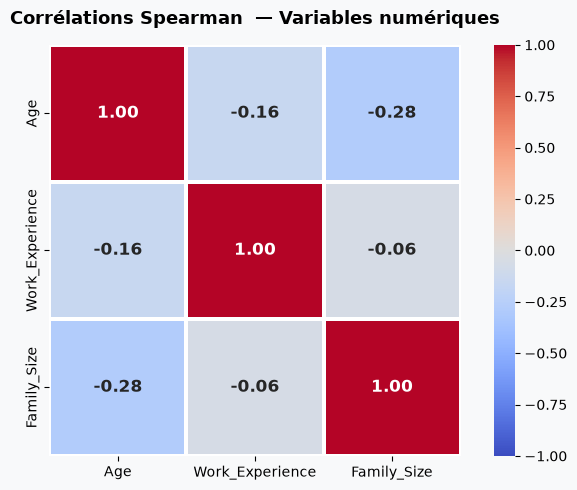

In [19]:
## Numériques x Numériques

corr = df_train[num_vars].corr(method='spearman')

fig, ax = plt.subplots(figsize=(7, 5))
fig.patch.set_facecolor('#F8F9FA')
ax.set_facecolor('#F8F9FA')

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1,
            linewidths=1.5, linecolor='white',
            square=True, ax=ax,
            annot_kws={'size': 12, 'weight': 'bold'})

ax.set_title('Corrélations Spearman  — Variables numériques',
             fontsize=13, fontweight='bold', pad=15)
ax.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.show()

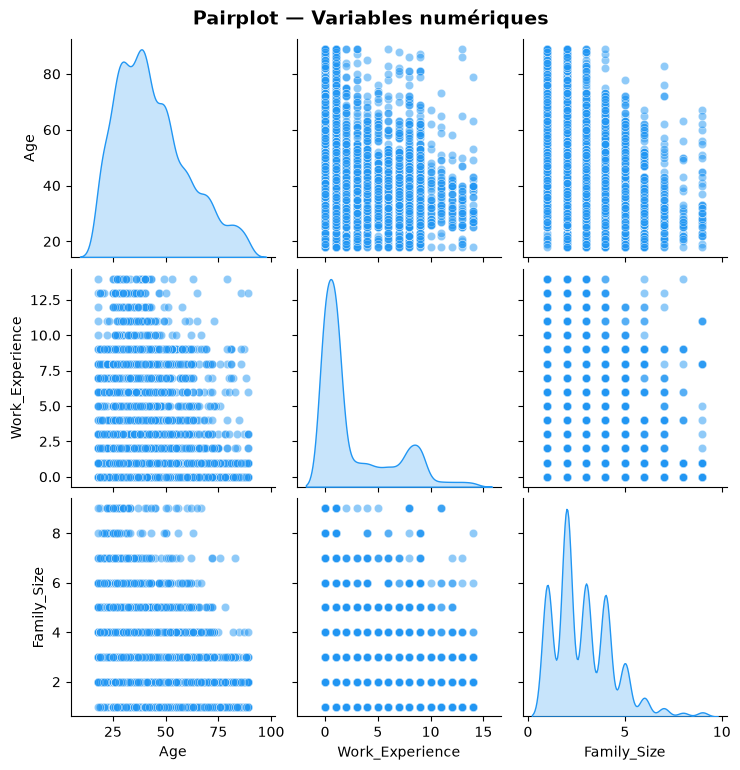

In [20]:
## Numériques x Numériques

pair_df = df_train[num_vars].copy()

g = sns.pairplot(pair_df, diag_kind='kde', plot_kws={'alpha': 0.5, 'color': '#2196F3'},
                 diag_kws={'color': '#2196F3', 'fill': True})

g.figure.suptitle('Pairplot — Variables numériques', fontsize=14,
                   fontweight='bold', y=1.02)
plt.show()

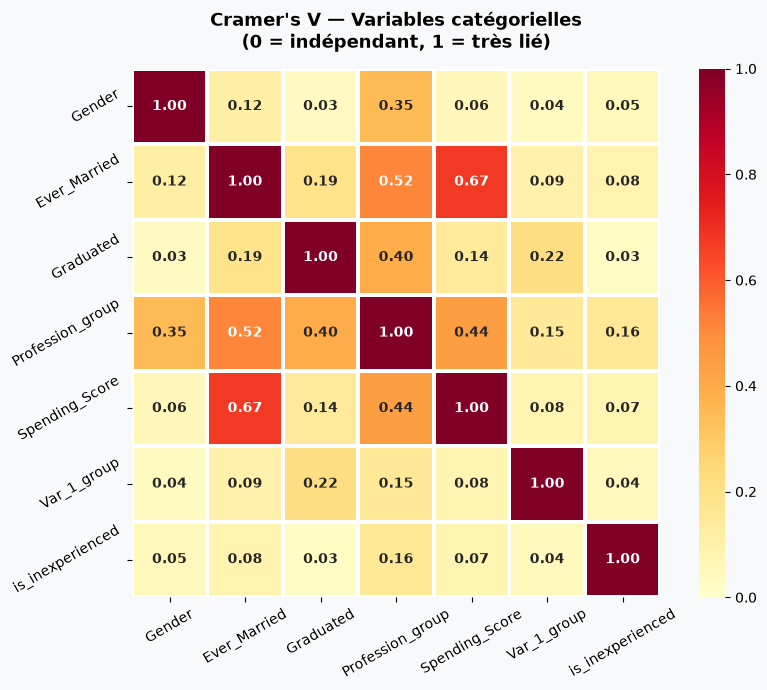

In [21]:
## Catégorielle x Catégorielle

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2, _, _, _ = chi2_contingency(ct)
    n = ct.sum().sum()
    r, k = ct.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# Matrice Cramér's V
cramers_matrix = pd.DataFrame(index=new_cat_vars, columns=new_cat_vars, dtype=float)

for col1 in new_cat_vars:
    for col2 in new_cat_vars:
        if col1 == col2:
            cramers_matrix.loc[col1, col2] = 1.0
        else:
            cramers_matrix.loc[col1, col2] = cramers_v(
                df_train[col1].dropna(), df_train[col2].dropna()
            )

fig, ax = plt.subplots(figsize=(9, 7))
fig.patch.set_facecolor('#F8F9FA')
ax.set_facecolor('#F8F9FA')

sns.heatmap(cramers_matrix.astype(float), annot=True, fmt='.2f',
            cmap='YlOrRd', vmin=0, vmax=1,
            linewidths=1.5, linecolor='white',
            square=True, ax=ax,
            annot_kws={'size': 10, 'weight': 'bold'})

ax.set_title("Cramer's V — Variables catégorielles\n(0 = indépendant, 1 = très lié)",
             fontsize=13, fontweight='bold', pad=15)
ax.tick_params(axis='both', labelsize=10, rotation=30)

plt.tight_layout()
plt.show()

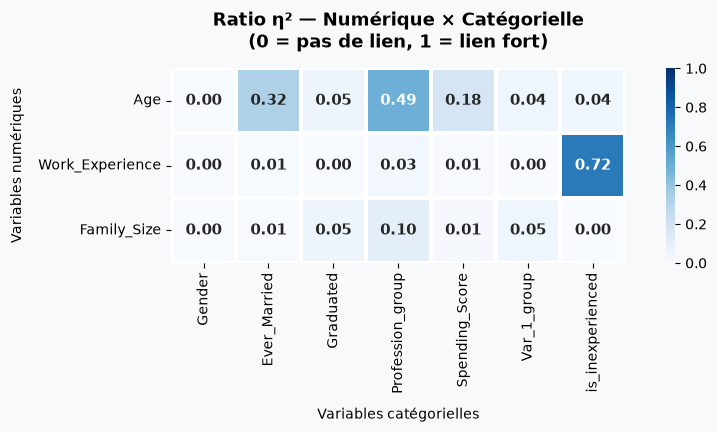

In [22]:
## Numérique x Catégorielle - Ration de Corrélation

def eta_squared(num_col, cat_col):
    temp = df_train[[num_col, cat_col]].dropna()
    
    groups = [temp[temp[cat_col] == cat][num_col]
              for cat in temp[cat_col].unique()]
    
    grand_mean = temp[num_col].mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in groups)
    ss_total = sum((temp[num_col] - grand_mean)**2)
    
    return ss_between / ss_total if ss_total != 0 else 0

eta_matrix = pd.DataFrame(index=num_vars, columns=new_cat_vars, dtype=float)

for num in num_vars:
    for cat in new_cat_vars:
        eta_matrix.loc[num, cat] = eta_squared(num, cat)

fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor('#F8F9FA')
ax.set_facecolor('#F8F9FA')

sns.heatmap(eta_matrix.astype(float), annot=True, fmt='.2f',
            cmap='Blues', vmin=0, vmax=1,
            linewidths=1.5, linecolor='white',
            square=True, ax=ax,
            annot_kws={'size': 11, 'weight': 'bold'})

ax.set_title("Ratio η² — Numérique × Catégorielle\n(0 = pas de lien, 1 = lien fort)",
             fontsize=13, fontweight='bold', pad=15)
ax.tick_params(axis='both', labelsize=10)
ax.set_xlabel('Variables catégorielles', labelpad=10)
ax.set_ylabel('Variables numériques', labelpad=10)

plt.tight_layout()
plt.show()

##### PREPROCESSING

###### Traitement des valeurs manquantes

In [23]:
print(num_vars)
print(new_cat_vars)

['Age', 'Work_Experience', 'Family_Size']
['Gender', 'Ever_Married', 'Graduated', 'Profession_group', 'Spending_Score', 'Var_1_group', 'is_inexperienced']


In [24]:
# Imputation de Work_Experience par la médiane
median_work_exp = X_train['Work_Experience'].median()
X_train['Work_Experience_imputed'] = X_train['Work_Experience'].fillna(median_work_exp)
X_test['Work_Experience_imputed']  = X_test['Work_Experience'].fillna(median_work_exp)

# Vérification
print(f"Médiane calculée sur le train : {median_work_exp}")
print(f"\nValeurs manquantes avant — Train : {X_train['Work_Experience'].isnull().sum()} | Test : {X_test['Work_Experience'].isnull().sum()}")
print(f"Valeurs manquantes après — Train : {X_train['Work_Experience_imputed'].isnull().sum()} | Test : {X_test['Work_Experience_imputed'].isnull().sum()}")

Médiane calculée sur le train : 1.0

Valeurs manquantes avant — Train : 646 | Test : 183
Valeurs manquantes après — Train : 0 | Test : 0


In [25]:
# Flag : 0 ou 1 an d'expérience imputé
X_train['is_inexperienced_imputed'] = X_train['Work_Experience_imputed'].apply(
    lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
)
X_test['is_inexperienced_imputed'] = X_test['Work_Experience_imputed'].apply(
    lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
)

# df_train['is_inexperienced_imputed'] = df_train['Work_Experience_imputed'].apply(
#     lambda x: 1 if pd.notna(x) and x <= 1 else (np.nan if pd.isna(x) else 0)
# )

In [26]:
# Médiane de Family_Size par segment
median_by_segment = X_train.copy()
median_by_segment['Segmentation'] = y_train.values
median_by_segment = median_by_segment.groupby('Segmentation')['Family_Size'].median()

print("Médianes par segment :")
print(median_by_segment)

# Imputation Train
X_train['Family_Size_imputed'] = X_train.copy().assign(
    Segmentation=y_train.values
).apply(
    lambda row: median_by_segment[row['Segmentation']]
    if pd.isnull(row['Family_Size'])
    else row['Family_Size'],
    axis=1
)

# Imputation Test (on utilise les médianes du train, appliquées via y_test)
X_test['Family_Size_imputed'] = X_test.copy().assign(
    Segmentation=y_test.values
).apply(
    lambda row: median_by_segment[row['Segmentation']]
    if pd.isnull(row['Family_Size'])
    else row['Family_Size'],
    axis=1
)

# Vérification
print(f"\nValeurs manquantes avant — Train : {X_train['Family_Size'].isnull().sum()} | Test : {X_test['Family_Size'].isnull().sum()}")
print(f"Valeurs manquantes après — Train : {X_train['Family_Size_imputed'].isnull().sum()} | Test : {X_test['Family_Size_imputed'].isnull().sum()}")

Médianes par segment :
Segmentation
A    2.0
B    2.0
C    3.0
D    3.0
Name: Family_Size, dtype: float64

Valeurs manquantes avant — Train : 264 | Test : 71
Valeurs manquantes après — Train : 0 | Test : 0


In [27]:
cat_vars_to_impute = ['Ever_Married', 'Graduated', 'Profession_group', 'Var_1_group']

for col in cat_vars_to_impute:
    # Mode par segment
    mode_by_segment = X_train.copy()
    mode_by_segment['Segmentation'] = y_train.values
    mode_by_segment = mode_by_segment.groupby('Segmentation')[col].agg(
        lambda x: x.mode()[0]
    )

    print(f"Mode '{col}' par segment :")
    print(mode_by_segment, '\n')

    col_imputed = f'{col}_imputed'

    # Imputation Train
    X_train[col_imputed] = X_train.copy().assign(
        Segmentation=y_train.values
    ).apply(
        lambda row: mode_by_segment[row['Segmentation']]
        if pd.isnull(row[col])
        else row[col],
        axis=1
    )

    # Imputation Test
    X_test[col_imputed] = X_test.copy().assign(
        Segmentation=y_test.values
    ).apply(
        lambda row: mode_by_segment[row['Segmentation']]
        if pd.isnull(row[col])
        else row[col],
        axis=1
    )

    # Vérification
    print(f"Manquants avant — Train : {X_train[col].isnull().sum()} | Test : {X_test[col].isnull().sum()}")
    print(f"Manquants après — Train : {X_train[col_imputed].isnull().sum()} | Test : {X_test[col_imputed].isnull().sum()}")
    print("-" * 50)

Mode 'Ever_Married' par segment :
Segmentation
A    Yes
B    Yes
C    Yes
D     No
Name: Ever_Married, dtype: str 

Manquants avant — Train : 111 | Test : 29
Manquants après — Train : 0 | Test : 0
--------------------------------------------------
Mode 'Graduated' par segment :
Segmentation
A    Yes
B    Yes
C    Yes
D     No
Name: Graduated, dtype: str 

Manquants avant — Train : 59 | Test : 19
Manquants après — Train : 0 | Test : 0
--------------------------------------------------
Mode 'Profession_group' par segment :
Segmentation
A        Artist
B        Artist
C        Artist
D    Healthcare
Name: Profession_group, dtype: str 

Manquants avant — Train : 106 | Test : 18
Manquants après — Train : 0 | Test : 0
--------------------------------------------------
Mode 'Var_1_group' par segment :
Segmentation
A    Cat_6
B    Cat_6
C    Cat_6
D    Cat_6
Name: Var_1_group, dtype: str 

Manquants avant — Train : 60 | Test : 16
Manquants après — Train : 0 | Test : 0
-------------------------

In [28]:
X_train.columns

Index(['ID', 'Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession',
       'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1', 'Age_bin',
       'Work_Experience_bin', 'Family_Size_bin', 'Profession_group',
       'Var_1_group', 'is_inexperienced', 'Work_Experience_imputed',
       'is_inexperienced_imputed', 'Family_Size_imputed',
       'Ever_Married_imputed', 'Graduated_imputed', 'Profession_group_imputed',
       'Var_1_group_imputed'],
      dtype='str')

###### Pipeline Preprocessing

In [186]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, RobustScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate, StratifiedKFold, cross_val_score
import optuna
from optuna.samplers import TPESampler
import shap

In [30]:
num_vars_imputed = ['Age' ,'Work_Experience_imputed', 'Family_Size_imputed']
new_cat_vars_imputed_ohe = ['Gender', 'Ever_Married_imputed', 'Graduated_imputed', 'Profession_group_imputed', 'Var_1_group_imputed',
                         'is_inexperienced_imputed']
cat_vars_ord = ['Spending_Score']

new_cat_vars_ohe = ['Gender', 'Ever_Married', 'Graduated', 'Profession_group', 'Var_1_group', 'is_inexperienced']

In [31]:
X_train['Spending_Score'].unique()

<StringArray>
['Low', 'Average', 'High']
Length: 3, dtype: str

In [32]:
# ── Preprocessors ───────────────────────────────────────
# Pour modèle linéaire — OHE + Scaler
prep_linear = ColumnTransformer([
    ('num', RobustScaler(), num_vars_imputed),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), new_cat_vars_imputed_ohe),
    ('ord', OrdinalEncoder(categories=[['Low', 'Average', 'High']]),  cat_vars_ord),
], remainder='drop')

# Pour ensemble (RF)
prep_ensemble = ColumnTransformer([
    ('num', 'passthrough', num_vars_imputed),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False),  new_cat_vars_imputed_ohe),
    ('ord', OrdinalEncoder(categories=[['Low', 'Average', 'High']]),  cat_vars_ord),
], remainder='drop')

# Pour Boosting
all_vars = num_vars + new_cat_vars_ohe + cat_vars_ord

def encode_categoricals(X):
    X = X[all_vars].copy()
    for col in new_cat_vars_ohe + cat_vars_ord:
        X[col] = X[col].astype(str).astype('category')
    return X

X_train_cat = encode_categoricals(X_train)
X_test_cat  = encode_categoricals(X_test)

In [ ]:
# ── Logistic Regression ──────────────────────────────────
pipe_lr = Pipeline([
    ('prep',  prep_linear),
    ('model', LogisticRegression(
    C=1.0,                    
    penalty='l2',             
    solver='saga',            
    l1_ratio=0.5,             
    max_iter=1000,
    class_weight='balanced',
    random_state=42
))
])

# ── Random Forest ────────────────────────────────────────
pipe_rf = Pipeline([
    ('prep',  prep_ensemble),
    ('model', RandomForestClassifier(
    n_estimators=200,
    max_depth=5,           
    min_samples_split=20,  
    min_samples_leaf=10,   
    max_features='sqrt',   
    max_samples=0.8,       
    class_weight='balanced',
    random_state=42
))
])

# ── XGBoost  ───────────────────────────
xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,      
    max_depth=4,             
    min_child_weight=5,      
    subsample=0.8,           
    colsample_bytree=0.8,    
    colsample_bylevel=0.8,   
    reg_alpha=0.1,           
    reg_lambda=1.0,          
    gamma=0.1,               
    enable_categorical=True,
    tree_method='hist',
    eval_metric='mlogloss',
    random_state=42
)

# xgb_model = XGBClassifier(
#     n_estimators=781,
#     learning_rate=0.010846522335543837,      
#     max_depth=5,             
#     min_child_weight=2,      
#     subsample=0.7814136542688896,           
#     colsample_bytree=0.645728476170832,    
#     colsample_bylevel=0.9645327975998171,   
#     reg_alpha=0.0016243743988245349,           
#     reg_lambda=2.1035394219859644,          
#     gamma=0.7312278980383012,               
#     enable_categorical=True,
#     tree_method='hist',
#     eval_metric='mlogloss',
#     random_state=42
# )

# ── LightGBM  ──────────────────────────
lgbm_model = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    num_leaves=20,           
    min_child_samples=20,    
    subsample=0.8,           
    subsample_freq=1,        
    colsample_bytree=0.8,    
    reg_alpha=0.1,           
    reg_lambda=1.0,          
    random_state=42,
    verbose=-1
)

In [60]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

In [ ]:
# ── LR & RF via Pipeline ─────────────────────────────────
for name, pipe in [('Logistic Regression', pipe_lr), ('Random Forest', pipe_rf)]:
    res = cross_validate(pipe, X_train, y_train, cv=cv,
                         scoring='f1_macro',
                         return_train_score=True,
                         n_jobs=-1)
    cv_results[name] = res
    print(f" {name}")
    print(f"   Train F1 : {res['train_score'].mean():.4f} ± {res['train_score'].std():.4f}")
    print(f"   Val   F1 : {res['test_score'].mean():.4f}  ± {res['test_score'].std():.4f}\n")

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc  = le.transform(y_test)

# print("Classes encodées :", le.classes_)  # ['A' 'B' 'C' 'D']
# print("Mapping :", dict(zip(le.classes_, le.transform(le.classes_))))

# ── XGBoost ──────────────────────────────────────────────
res_xgb = cross_validate(xgb_model, X_train_cat, y_train_enc, cv=cv,
                          scoring='f1_macro',
                          return_train_score=True
                          )
cv_results['XGBoost'] = res_xgb
print(f" XGBoost")
print(f"   Train F1 : {res_xgb['train_score'].mean():.4f} ± {res_xgb['train_score'].std():.4f}")
print(f"   Val   F1 : {res_xgb['test_score'].mean():.4f}  ± {res_xgb['test_score'].std():.4f}\n")

# ── LightGBM ─────────────────────────────────────────────
res_lgbm = cross_validate(lgbm_model, X_train_cat, y_train_enc, cv=cv,
                           scoring='f1_macro',
                           return_train_score=True
                           )
cv_results['LightGBM'] = res_lgbm
print(f" LightGBM")
print(f"   Train F1 : {res_lgbm['train_score'].mean():.4f} ± {res_lgbm['train_score'].std():.4f}")
print(f"   Val   F1 : {res_lgbm['test_score'].mean():.4f}  ± {res_lgbm['test_score'].std():.4f}\n")

 Logistic Regression
   Train F1 : 0.4956 ± 0.0045
   Val   F1 : 0.4874  ± 0.0101

 Random Forest
   Train F1 : 0.5229 ± 0.0055
   Val   F1 : 0.5036  ± 0.0109



In [41]:
# summary = pd.DataFrame({
#     'Train F1 (mean)': [cv_results[n]['train_score'].mean() for n in cv_results],
#     'Train F1 (std)':  [cv_results[n]['train_score'].std()  for n in cv_results],
#     'Val F1 (mean)':   [cv_results[n]['test_score'].mean()  for n in cv_results],
#     'Val F1 (std)':    [cv_results[n]['test_score'].std()   for n in cv_results],
#     'Gap Train-Val':   [cv_results[n]['train_score'].mean() -
#                         cv_results[n]['test_score'].mean()  for n in cv_results],
# }, index=cv_results.keys()).round(4)

# print(summary)

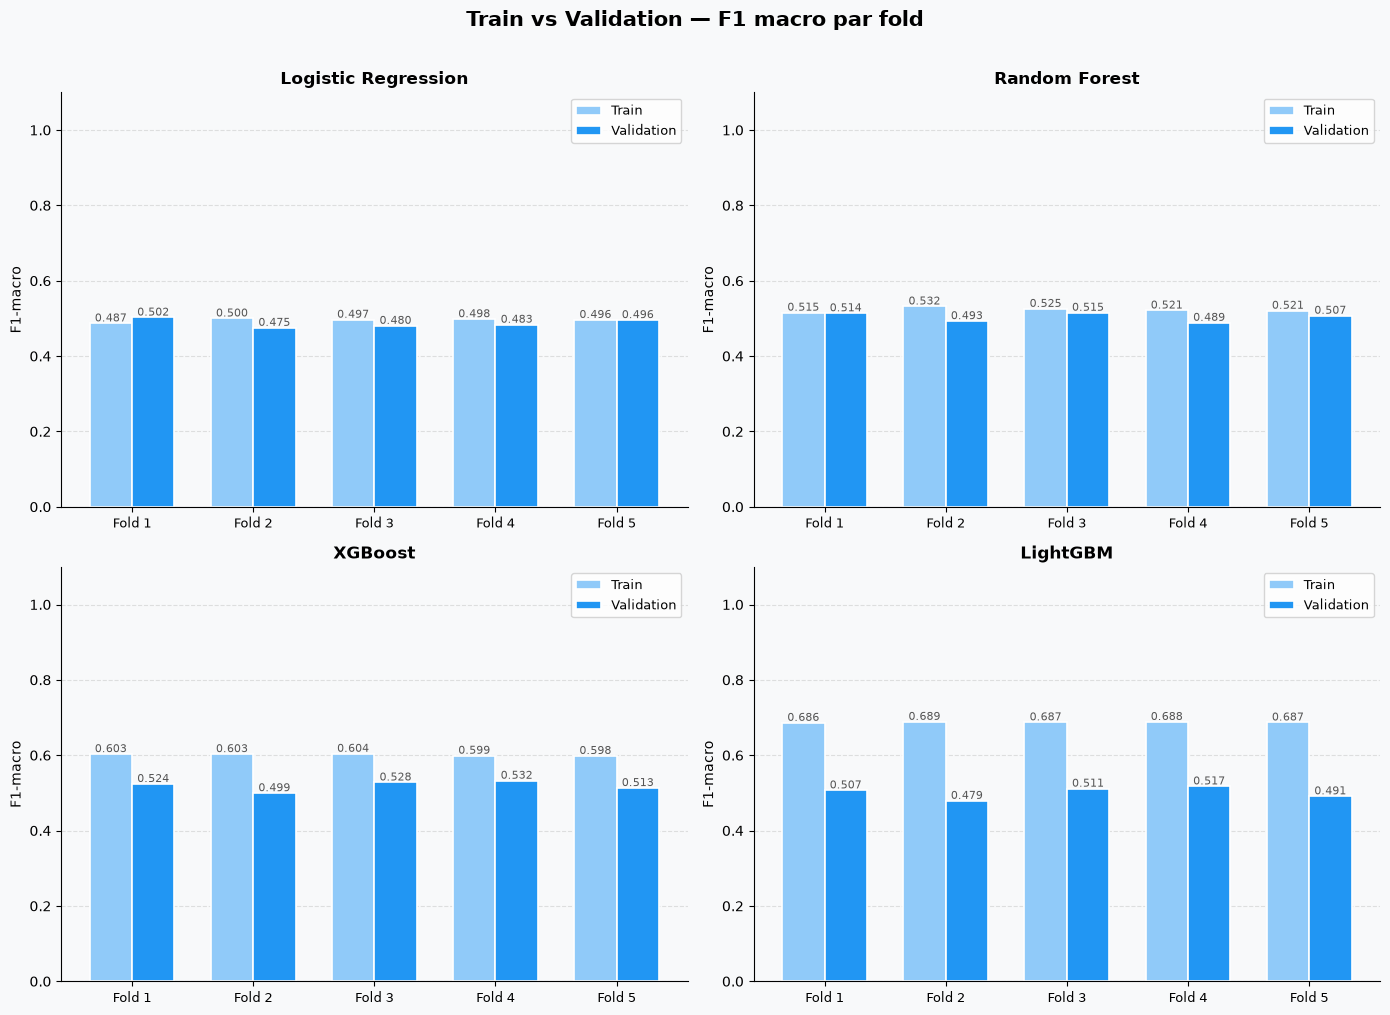

In [64]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Train vs Validation — F1 macro par fold', fontsize=15,
             fontweight='bold', y=1.01)
fig.patch.set_facecolor('#F8F9FA')

colors_train = '#90CAF9'   # bleu clair
colors_val   = '#2196F3'   # bleu foncé
folds = [f'Fold {i+1}' for i in range(5)]

for ax, (name, res) in zip(axes.flatten(), cv_results.items()):
    ax.set_facecolor('#F8F9FA')
    x = np.arange(5)
    width = 0.35

    bars_train = ax.bar(x - width/2, res['train_score'], width,
                        label='Train', color=colors_train,
                        edgecolor='white', linewidth=1.2)
    bars_val   = ax.bar(x + width/2, res['test_score'],  width,
                        label='Validation', color=colors_val,
                        edgecolor='white', linewidth=1.2)

    # Annotations
    for bar in bars_train:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', fontsize=8, color='#555')
    for bar in bars_val:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', fontsize=8, color='#555')

    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(folds, fontsize=9)
    ax.set_ylim(0, 1.1)
    ax.set_ylabel('F1-macro', fontsize=10)
    ax.legend(fontsize=9)
    ax.yaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

# Cacher le 4e subplot si seulement 4 modèles
if len(cv_results) < 4:
    axes.flatten()[-1].set_visible(False)

plt.tight_layout()
plt.show()

choix de l'algorithme : XGBoost

##### FEATURES ENGINEERING : pour améliorer le score

In [ ]:
# Âge auquel la personne a commencé à travailler
X_train_cat['start_work_age'] = X_train_cat['Age'] - X_train_cat['Work_Experience']

# Diplômé ET marié → profil stable
X_train_cat['stable_profile'] = ((X_train_cat['Graduated'] == 'Yes') &
                         (X_train_cat['Ever_Married'] == 'Yes')).astype(int)

# Non diplômé mais expérimenté → autodidacte
X_train_cat['experienced_no_degree'] = ((X_train_cat['Graduated'] == 'No') &
                                 (X_train_cat['Work_Experience'] > 5)).astype(int)

# Grande famille → contraintes financières probables
X_train_cat['large_family'] = (X_train_cat['Family_Size'] >= 4).astype(int)

# Célibataire sans enfants (proxy)
X_train_cat['single_no_family'] = ((X_train_cat['Ever_Married'] == 'No') &
                            (X_train_cat['Family_Size'] == 1)).astype(int)

# Score de "richesse estimée" : expérience élevée + petite famille + haut spending
spending_map = {'Low': 0, 'Average': 1, 'High': 2}
# X_train_cat['spending_num'] = X_train_cat['Spending_Score'].map(spending_map)
X_train_cat['spending_num'] = X_train_cat['Spending_Score'].map(spending_map).astype(float)

# Score de "stabilité" : marié + diplômé + expérimenté
X_train_cat['stability_score'] = (
    (X_train_cat['Ever_Married'] == 'Yes').astype(int) +
    (X_train_cat['Graduated'] == 'Yes').astype(int) +
    (X_train_cat['Work_Experience'] > 3).astype(int)
)

# Expérience moyenne par profession
exp_by_prof = X_train_cat.groupby('Profession_group')['Work_Experience'].transform('mean')
X_train_cat['exp_vs_profession_mean'] = X_train_cat['Work_Experience'] - exp_by_prof

# Taille de famille moyenne par groupe Var_1
fam_by_var1 = X_train_cat.groupby('Var_1_group')['Family_Size'].transform('mean')
X_train_cat['family_vs_var1_mean'] = X_train_cat['Family_Size'] - fam_by_var1

# Âge moyen par profession
age_by_prof = X_train_cat.groupby('Profession_group')['Age'].transform('mean')
X_train_cat['age_vs_profession_mean'] = X_train_cat['Age'] - age_by_prof

In [ ]:
# Âge auquel la personne a commencé à travailler
X_test_cat['start_work_age'] = X_test_cat['Age'] - X_test_cat['Work_Experience']

# Diplômé ET marié → profil stable
X_test_cat['stable_profile'] = ((X_test_cat['Graduated'] == 'Yes') &
                         (X_test_cat['Ever_Married'] == 'Yes')).astype(int)

# Non diplômé mais expérimenté → autodidacte
X_test_cat['experienced_no_degree'] = ((X_test_cat['Graduated'] == 'No') &
                                 (X_test_cat['Work_Experience'] > 5)).astype(int)

# Grande famille → contraintes financières probables
X_test_cat['large_family'] = (X_test_cat['Family_Size'] >= 4).astype(int)

# Célibataire sans enfants (proxy)
X_test_cat['single_no_family'] = ((X_test_cat['Ever_Married'] == 'No') &
                            (X_test_cat['Family_Size'] == 1)).astype(int)

# Score de "richesse estimée" : expérience élevée + petite famille + haut spending
spending_map = {'Low': 0, 'Average': 1, 'High': 2}
# X_test_cat['spending_num'] = X_test_cat['Spending_Score'].map(spending_map)
X_test_cat['spending_num'] = X_test_cat['Spending_Score'].map(spending_map).astype(float)

# Score de "stabilité" : marié + diplômé + expérimenté
X_test_cat['stability_score'] = (
    (X_test_cat['Ever_Married'] == 'Yes').astype(int) +
    (X_test_cat['Graduated'] == 'Yes').astype(int) +
    (X_test_cat['Work_Experience'] > 3).astype(int)
)

# Expérience moyenne par profession
exp_by_prof = X_test_cat.groupby('Profession_group')['Work_Experience'].transform('mean')
X_test_cat['exp_vs_profession_mean'] = X_test_cat['Work_Experience'] - exp_by_prof

# Taille de famille moyenne par groupe Var_1
fam_by_var1 = X_test_cat.groupby('Var_1_group')['Family_Size'].transform('mean')
X_test_cat['family_vs_var1_mean'] = X_test_cat['Family_Size'] - fam_by_var1

# Âge moyen par profession
age_by_prof = X_test_cat.groupby('Profession_group')['Age'].transform('mean')
X_test_cat['age_vs_profession_mean'] = X_test_cat['Age'] - age_by_prof

###### Tuning Optuna

In [170]:
optuna.logging.set_verbosity(optuna.logging.WARNING)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def objective(trial):

    params = {
        # Complexité des arbres
        'max_depth'         : trial.suggest_int('max_depth', 2, 8),
        'min_child_weight'  : trial.suggest_int('min_child_weight', 1, 20),
        'gamma'             : trial.suggest_float('gamma', 0.0, 1.0),

        # Sous-échantillonnage (anti-overfit)
        'subsample'         : trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree'  : trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'colsample_bylevel' : trial.suggest_float('colsample_bylevel', 0.5, 1.0),

        # Régularisation
        'reg_alpha'         : trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda'        : trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),

        # Learning rate + nombre d'arbres
        'learning_rate'     : trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'n_estimators'      : trial.suggest_int('n_estimators', 100, 800),

        # Fixés
        'enable_categorical': True,
        'tree_method'       : 'hist',
        'eval_metric'       : 'mlogloss',
        'random_state'      : 42,
        'n_jobs'            : -1,
        'class_weight'      : 'balanced',
    }

    model = XGBClassifier(**params)

    scores = cross_val_score(model, X_train_cat, y_train_enc,
                             cv=cv, scoring='f1_macro', n_jobs=-1)
    return scores.mean()


# ── Lancement de l'optimisation ──────────────────────────
study = optuna.create_study(
    direction='maximize',
    sampler=TPESampler(seed=42),
    study_name='xgb_segmentation'
)

study.optimize(objective, n_trials=100, show_progress_bar=True)

# ── Résultats ─────────────────────────────────────────────
print(f"\n Meilleur Val F1-macro : {study.best_value:.4f}")
print(f"\n Meilleurs hyperparamètres :")
for k, v in study.best_params.items():
    print(f"   {k:<25} : {v}")

Best trial: 75. Best value: 0.519492: 100%|██████████| 100/100 [09:16<00:00,  5.57s/it]


 Meilleur Val F1-macro : 0.5195

 Meilleurs hyperparamètres :
   max_depth                 : 3
   min_child_weight          : 18
   gamma                     : 0.7718160684252975
   subsample                 : 0.5756412265312737
   colsample_bytree          : 0.7643365692189418
   colsample_bylevel         : 0.7790928205116051
   reg_alpha                 : 0.0018703172467541052
   reg_lambda                : 1.8026034298233224
   learning_rate             : 0.012545786628984926
   n_estimators              : 499


###### Early stopping

In [167]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_scores = []
val_scores   = []
best_iterations = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X_train_cat, y_train_enc)):

    X_fold_train = X_train_cat.iloc[train_idx]
    X_fold_val   = X_train_cat.iloc[val_idx]
    y_fold_train = y_train_enc[train_idx] 
    y_fold_val   = y_train_enc[val_idx]  

    model = XGBClassifier(
        n_estimators=499,
        learning_rate=0.012545786628984926,
        max_depth=3,
        min_child_weight=18,
        subsample=0.5756412265312737,
        colsample_bytree=0.7643365692189418,
        colsample_bylevel=0.7790928205116051,
        reg_alpha=0.0018703172467541052,
        reg_lambda=1.8026034298233224,
        gamma=0.7718160684252975,
        enable_categorical=True,
        tree_method='hist',
        eval_metric='mlogloss',
        early_stopping_rounds=30,   # arrête si pas d'amélioration sur 30 rounds
        random_state=42,
        n_jobs=-1,
        verbosity=0,
        class_weight='balanced'
    )

    model.fit(
        X_fold_train, y_fold_train,
        eval_set=[(X_fold_val, y_fold_val)],  # surveille la val à chaque round
        verbose=False
    )

    best_iterations.append(model.best_iteration)

    y_pred_train = model.predict(X_fold_train)
    y_pred_val   = model.predict(X_fold_val)

    train_scores.append(f1_score(y_fold_train, y_pred_train, average='macro'))
    val_scores.append(f1_score(y_fold_val,   y_pred_val,   average='macro'))

    print(f"  Fold {fold+1} | Train F1: {train_scores[-1]:.4f} | "
          f"Val F1: {val_scores[-1]:.4f} | "
          f"Best iteration: {best_iterations[-1]}")

print(f"\n{'='*55}")
print(f"  Train F1 : {np.mean(train_scores):.4f} ± {np.std(train_scores):.4f}")
print(f"  Val   F1 : {np.mean(val_scores):.4f}  ± {np.std(val_scores):.4f}")
print(f"  Nb arbres moyen utilisé : {int(np.mean(best_iterations))}")

  Fold 1 | Train F1: 0.5499 | Val F1: 0.5200 | Best iteration: 496
  Fold 2 | Train F1: 0.5560 | Val F1: 0.4968 | Best iteration: 498
  Fold 3 | Train F1: 0.5480 | Val F1: 0.5222 | Best iteration: 498
  Fold 4 | Train F1: 0.5498 | Val F1: 0.5299 | Best iteration: 498
  Fold 5 | Train F1: 0.5419 | Val F1: 0.5186 | Best iteration: 498

  Train F1 : 0.5491 ± 0.0045
  Val   F1 : 0.5175  ± 0.0111
  Nb arbres moyen utilisé : 497


###### Entraînement du modèle final avec les meileurs hyperparamètres

In [172]:
best_params = study.best_params
best_params.update({
    'enable_categorical': True,
    'tree_method'       : 'hist',
    'eval_metric'       : 'mlogloss',
    'random_state'      : 42,
    'n_jobs'            : -1,
    'class_weight'      : 'balanced',
})

xgb_tuned = XGBClassifier(**best_params)

# # Validation croisée finale pour confirmer
# scores_tuned = cross_val_score(xgb_tuned, X_train_cat, y_train_enc,
#                                 cv=cv, scoring='f1_macro', n_jobs=-1)

# print(f"\n CV Val F1 (tuned)   : {scores_tuned.mean():.4f} ± {scores_tuned.std():.4f}")
# print(f" CV Val F1 (baseline): 0.5109 ± 0.0121")
# print(f" Gain                : +{scores_tuned.mean() - 0.5109:.4f}")

# Entraînement final sur tout X_train
xgb_tuned.fit(X_train_cat, y_train_enc)

# Évaluation sur le test set
y_pred_tuned = xgb_tuned.predict(X_test_cat)
f1_test_tuned = f1_score(y_test_enc, y_pred_tuned, average='macro')

print(f"\n Test F1-macro (tuned) : {f1_test_tuned:.4f}")
print(f"\n{classification_report(y_test_enc, y_pred_tuned)}")


 Test F1-macro (tuned) : 0.5285

              precision    recall  f1-score   support

           0       0.45      0.45      0.45       394
           1       0.43      0.32      0.37       372
           2       0.58      0.59      0.59       394
           3       0.65      0.77      0.70       454

    accuracy                           0.55      1614
   macro avg       0.53      0.53      0.53      1614
weighted avg       0.53      0.55      0.54      1614



###### features importance

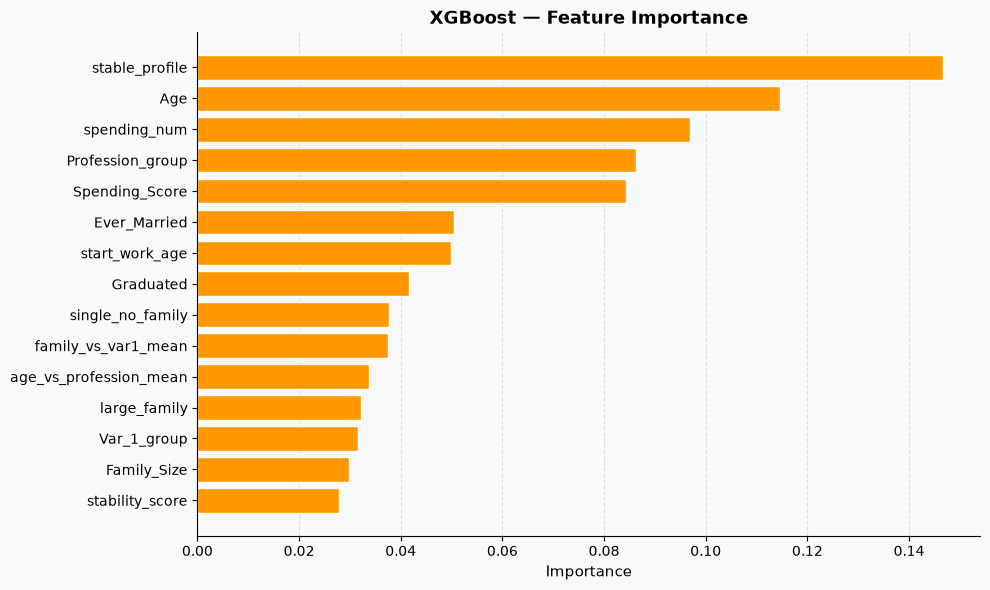

In [173]:
# xgb_model = XGBClassifier(
#     n_estimators=499,
#     learning_rate=0.012545786628984926,
#     max_depth=3,
#     min_child_weight=18,
#     subsample=0.5756412265312737,
#     colsample_bytree=0.7643365692189418,
#     colsample_bylevel=0.7790928205116051,
#     reg_alpha=0.0018703172467541052,
#     reg_lambda=1.8026034298233224,
#     gamma=0.7718160684252975,
#     enable_categorical=True,
#     tree_method='hist',
#     eval_metric='mlogloss',
#     random_state=42,
#     n_jobs=-1,
#     verbosity=0
# )

# xgb_model.fit(X_train_cat, y_train_enc)
fi_xgb = pd.Series(xgb_tuned.feature_importances_,
                   index=X_train_cat.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('#F8F9FA')
ax.set_facecolor('#F8F9FA')
ax.barh(fi_xgb.index[::-1], fi_xgb.values[::-1], color='#FF9800', edgecolor='white')
ax.set_title('XGBoost — Feature Importance', fontsize=13, fontweight='bold')
ax.set_xlabel('Importance', fontsize=11)
ax.xaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()


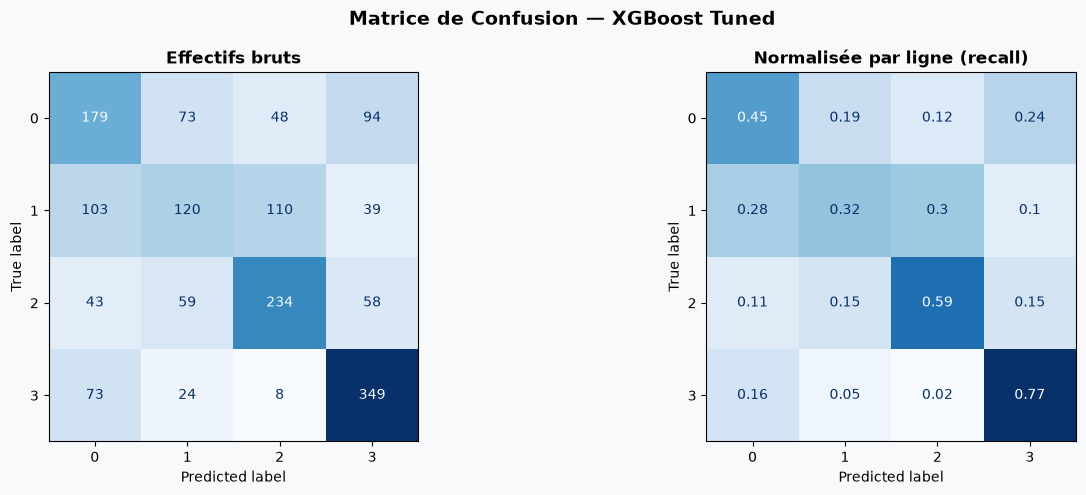

In [187]:
cm = confusion_matrix(y_test_enc, y_pred_tuned)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor('#F8F9FA')
fig.suptitle('Matrice de Confusion — XGBoost Tuned', fontsize=14, fontweight='bold')

# ── Valeurs absolues ──────────────────────────────────────
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=[0, 1, 2, 3])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Effectifs bruts', fontsize=12, fontweight='bold')
axes[0].set_facecolor('#F8F9FA')

# ── Valeurs normalisées (% par ligne = recall réel) ───────
cm_norm = confusion_matrix(y_test_enc, y_pred_tuned, normalize='true')
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm.round(2),
                                    display_labels=[0, 1, 2, 3])
disp_norm.plot(ax=axes[1], colorbar=False, cmap='Blues')
axes[1].set_title('Normalisée par ligne (recall)', fontsize=12, fontweight='bold')
axes[1].set_facecolor('#F8F9FA')

plt.tight_layout()
plt.show()

In [178]:
explainer = shap.TreeExplainer(xgb_tuned)

# S'assurer que X_test_cat a bien toutes les colonnes
print(X_test_cat.shape)          # doit afficher (n_lignes, 10)
print(X_test_cat.columns.tolist())

# Calculer les SHAP values
shap_values = explainer.shap_values(X_test_cat)

# Vérifier la forme
print(type(shap_values))         # liste de 4 arrays (un par classe) ou array 3D
print(np.array(shap_values).shape)

(1614, 20)
['Age', 'Work_Experience', 'Family_Size', 'Gender', 'Ever_Married', 'Graduated', 'Profession_group', 'Var_1_group', 'is_inexperienced', 'Spending_Score', 'start_work_age', 'stable_profile', 'experienced_no_degree', 'large_family', 'single_no_family', 'spending_num', 'stability_score', 'exp_vs_profession_mean', 'family_vs_var1_mean', 'age_vs_profession_mean']
<class 'numpy.ndarray'>
(1614, 20, 4)


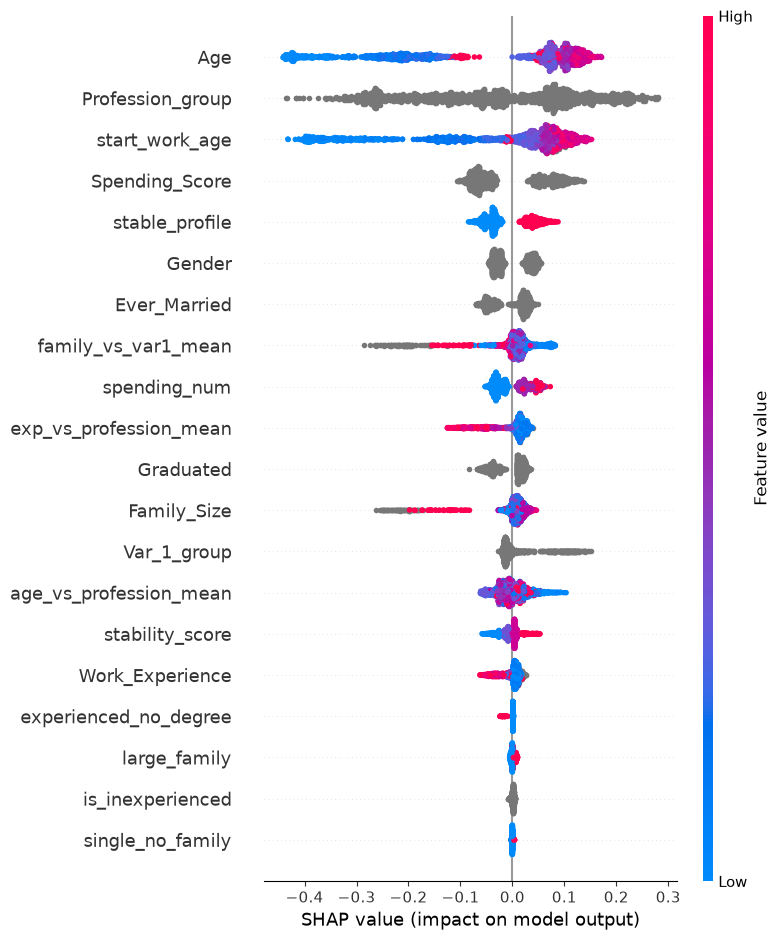

In [185]:
# Cas 1 : shap_values est une liste de 4 arrays (un par classe)
if isinstance(shap_values, list):
    # Summary plot global (toutes classes confondues)
    shap.summary_plot(shap_values, X_test_cat, plot_type='bar',
                      class_names=['Seg 0', 'Seg 1', 'Seg 2', 'Seg 3'])

    # Detail par classe — ex : segment 1 (le plus difficile)
    shap.summary_plot(shap_values[1], X_test_cat,
                      title='SHAP — Segment 1')

# Cas 2 : array 3D (n_samples, n_features, n_classes)
else:
    shap.summary_plot(shap_values[:, :, 1], X_test_cat,
                      title='SHAP — Segment 1')

In [78]:
# pipe_lr.fit(X_train, y_train)
# prep_fitted = pipe_lr.named_steps['prep']
# ohe_features = prep_fitted.named_transformers_['cat']\
#                            .get_feature_names_out(new_cat_vars_imputed_ohe).tolist()

# feature_names = num_vars_imputed + ohe_features + cat_vars_ord

# lr_model = pipe_lr.named_steps['model']
# coefs = np.abs(lr_model.coef_).mean(axis=0)  # moyenne sur les 4 classes

# fi_lr = pd.Series(coefs, index=feature_names).sort_values(ascending=False).head(15)

# fig, ax = plt.subplots(figsize=(10, 6))
# fig.patch.set_facecolor('#F8F9FA')
# ax.set_facecolor('#F8F9FA')
# ax.barh(fi_lr.index[::-1], fi_lr.values[::-1], color='#2196F3', edgecolor='white')
# ax.set_title('Logistic Regression — Importance (|coef| moyen)', fontsize=13, fontweight='bold')
# ax.set_xlabel('|Coefficient| moyen', fontsize=11)
# ax.xaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
# ax.set_axisbelow(True)
# ax.spines[['top', 'right']].set_visible(False)
# plt.tight_layout()
# plt.show()

In [79]:
# pipe_lr.fit(X_train, y_train)
# pipe_rf.fit(X_train, y_train)
# xgb_model.fit(X_train_cat, y_train_enc)
# lgbm_model.fit(X_train_cat, y_train_enc,
#                categorical_feature=new_cat_vars_ohe + cat_vars_ord)

In [80]:
# rf_model = pipe_rf.named_steps['model']
# fi_rf = pd.Series(rf_model.feature_importances_,
#                   index=feature_names).sort_values(ascending=False).head(15)

# fig, ax = plt.subplots(figsize=(10, 6))
# fig.patch.set_facecolor('#F8F9FA')
# ax.set_facecolor('#F8F9FA')
# ax.barh(fi_rf.index[::-1], fi_rf.values[::-1], color='#4CAF50', edgecolor='white')
# ax.set_title('Random Forest — Feature Importance (Gini)', fontsize=13, fontweight='bold')
# ax.set_xlabel('Importance', fontsize=11)
# ax.xaxis.grid(True, linestyle='--', alpha=0.6, color='#CCCCCC')
# ax.set_axisbelow(True)
# ax.spines[['top', 'right']].set_visible(False)
# plt.tight_layout()
# plt.show()